# Анализ продаж сети Rossmann

**Цель:** понять, что влияет на продажи сети магазинов: сезонность, число работающих точек и промо-акции.

**Вопросы:**
1. Как менялись продажи во времени, есть ли сезонность?
2. Чем объясняется спад выручки в 2014 году?
3. Насколько промо связано с ростом продаж и устойчива ли эта связь?
4. Какие магазины дают основную выручку (ABC-анализ)?

## 1. Знакомство с данными

In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.1f}'.format
plt.rcParams['figure.figsize'] = (12, 5)

train = pd.read_csv('train.csv', low_memory=False, parse_dates=['Date'])
store = pd.read_csv('store.csv')

print(train.shape, store.shape)
print(train['Date'].min().date(), '-', train['Date'].max().date())
print(train.isna().sum())
print(train['Open'].value_counts())
train.head()

(1017209, 9) (1115, 10)
2013-01-01 - 2015-07-31
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64
Open
1    844392
0    172817
Name: count, dtype: int64


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


**Вывод.** В `train.csv` 1 017 209 строк по 1 115 магазинам за период с 2013-01-01 по 2015-07-31, пропусков нет. Магазины были открыты в 844 392 случаях, закрыты — в 172 817.

## 2. Очистка и объединение таблиц

In [3]:
print('Открыт, но без продаж:', ((train['Open'] == 1) & (train['Sales'] == 0)).sum())

# оставляем дни, когда магазин работал и были продажи
df = train[(train['Open'] == 1) & (train['Sales'] > 0)].copy()

# добавляем справочник магазинов
df = df.merge(store, on='Store', how='left')
df['YearMonth'] = df['Date'].dt.to_period('M').astype(str)

print(df.shape)
print(df['Sales'].describe())

Открыт, но без продаж: 54
(844338, 19)
count   844,338.0
mean      6,956.0
std       3,103.8
min          46.0
25%       4,859.0
50%       6,369.0
75%       8,360.0
max      41,551.0
Name: Sales, dtype: float64


**Вывод.** Для анализа оставлено 844 338 строк: дни, когда магазин был открыт и были продажи. В 54 случаях магазин числился открытым без продаж, такие строки исключены. Продажи магазина за день: среднее 6 956, медиана 6 369, максимум 41 551. Среднее выше медианы: распределение смещено вправо из-за редких очень сильных дней.

## 3. Динамика выручки по месяцам

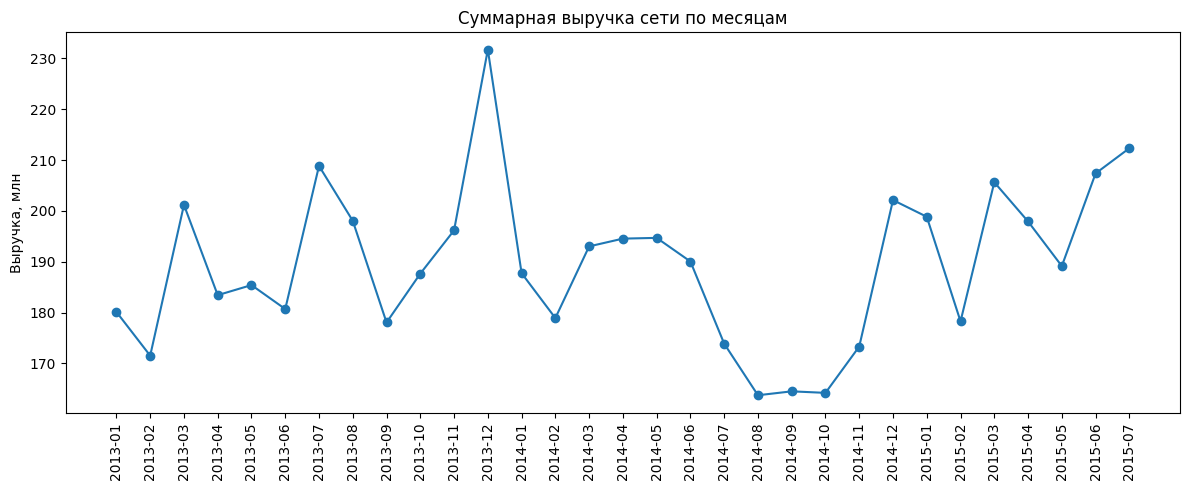

In [4]:
monthly = df.groupby('YearMonth').agg(
    revenue=('Sales', 'sum'),
    stores=('Store', 'nunique'),
    avg_sales=('Sales', 'mean'),
).reset_index()

plt.plot(monthly['YearMonth'], monthly['revenue'] / 1e6, marker='o')
plt.xticks(rotation=90)
plt.ylabel('Выручка, млн')
plt.title('Суммарная выручка сети по месяцам')
plt.tight_layout()
plt.show()

**Вывод.** Суммарная выручка максимальна в декабре 2013 (около 230 млн), в декабре 2014 пик ниже (около 200 млн). С июля по октябрь 2014 выручка самая низкая за весь период. Сравнивать месяцы по сумме некорректно: меняется число работающих магазинов (следующий раздел).

## 4. Спад 2014 года: сколько магазинов работало

In [5]:
print(monthly.set_index('YearMonth').loc['2014-04':'2014-12', 'stores'])

june = set(df.loc[df['YearMonth'] == '2014-06', 'Store'])
sept = set(df.loc[df['YearMonth'] == '2014-09', 'Store'])
mar15 = set(df.loc[df['YearMonth'] == '2015-03', 'Store'])

missing = june - sept
print('Пропали к сентябрю 2014:', len(missing))
print('Из них вернулись к марту 2015:', len(missing & mar15))

YearMonth
2014-04    1115
2014-05    1115
2014-06    1114
2014-07     934
2014-08     934
2014-09     934
2014-10     935
2014-11     935
2014-12     935
Name: stores, dtype: int64
Пропали к сентябрю 2014: 181
Из них вернулись к марту 2015: 181


**Вывод.** С июля 2014 в данных остаётся 934 магазина вместо 1 115 (на 181 меньше, около 16%). Все 181 магазин возвращаются к марту 2015. Это объясняет спад суммарной выручки. Причина отсутствия магазинов (по описанию датасета — временное закрытие на ремонт) самими данными напрямую не подтверждается.

## 5. Сезонность: средние продажи магазина в день

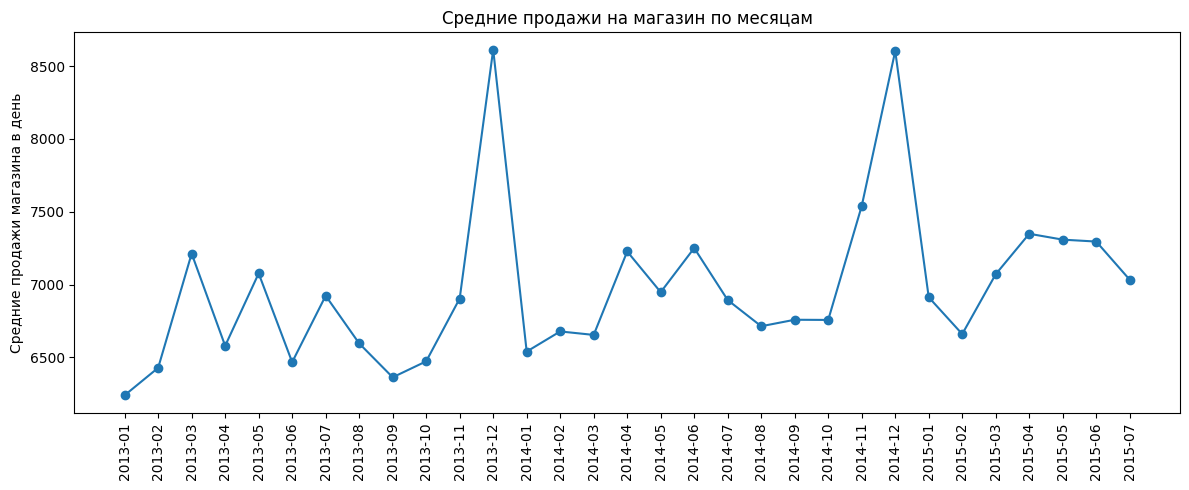

In [6]:
plt.plot(monthly['YearMonth'], monthly['avg_sales'], marker='o')
plt.xticks(rotation=90)
plt.ylabel('Средние продажи магазина в день')
plt.title('Средние продажи на магазин по месяцам')
plt.tight_layout()
plt.show()

**Вывод.** Средние продажи на магазин показывают одинаковый декабрьский пик в оба года (около 8 600). Сезонность подтверждается, а более низкий пик суммарной выручки в 2014 году объясняется меньшим числом работающих магазинов.

## 6. Промо-акции

In [7]:
# общее сравнение
promo = df.groupby('Promo')['Sales'].agg(['mean', 'median', 'count']).round(0)
print(promo)
print(f"Прирост средних продаж с промо: {promo.loc[1, 'mean'] / promo.loc[0, 'mean'] - 1:.1%}")

# по дням недели (промо бывает только в будни, поэтому сравниваем день с днём)
by_dow = df.groupby(['DayOfWeek', 'Promo'])['Sales'].mean().unstack().round(0)
by_dow['lift_%'] = ((by_dow[1] / by_dow[0] - 1) * 100).round(1)
print(by_dow)

wk = df[df['DayOfWeek'] <= 5].groupby('Promo')['Sales'].mean()
print(f"Прирост только по будням (Пн-Пт): {wk[1] / wk[0] - 1:.1%}")

# по каждому магазину отдельно
store_mean = df.groupby(['Store', 'Promo'])['Sales'].mean().unstack()
store_lift = (store_mean[1] / store_mean[0] - 1).dropna()
print(store_lift.describe())
print('Доля магазинов с ростом при промо:', round((store_lift > 0).mean(), 4))

         mean  median   count
Promo                        
0     5,930.0 5,459.0  467463
1     8,229.0 7,650.0  376875
Прирост средних продаж с промо: 38.8%
Promo           0       1  lift_%
DayOfWeek                        
1         6,223.0 9,773.0    57.0
2         5,716.0 8,278.0    44.8
3         5,618.0 7,686.0    36.8
4         5,751.0 7,599.0    32.1
5         6,344.0 7,744.0    22.1
6         5,875.0     NaN     NaN
7         8,225.0     NaN     NaN
Прирост только по будням (Пн-Пт): 38.8%
count   1,115.0
mean        0.4
std         0.2
min        -0.1
25%         0.3
50%         0.4
75%         0.5
max         1.4
dtype: float64
Доля магазинов с ростом при промо: 0.9991


**Вывод.** В дни с промо средние продажи магазина выше: 8 229 против 5 930, то есть на 38,8% (медианы 7 650 и 5 459). Связь сохраняется при сравнении по дням недели: прирост 57,0% в понедельник, 44,8% во вторник, 36,8% в среду, 32,1% в четверг и 22,1% в пятницу. Промо в данных есть только в будни. Прирост наблюдается практически во всех магазинах: у 1 114 из 1 115 он положительный, медианный прирост по магазину около 41%.

**Ограничение.** Это связь, а не доказанная причина: акции проходят не случайно, а по календарю сети, поэтому часть различий может объясняться другими факторами.

## 7. SQL: ABC-анализ магазинов и промо по типам магазинов

In [8]:
con = sqlite3.connect(':memory:')
sales = df[['Store', 'Date', 'DayOfWeek', 'Sales', 'Promo', 'StoreType', 'Assortment']].copy()
sales['Date'] = sales['Date'].dt.strftime('%Y-%m-%d')
sales.to_sql('sales', con, index=False)

abc_query = """
WITH store_rev AS (
    SELECT Store, SUM(Sales) AS revenue
    FROM sales
    GROUP BY Store
),
ranked AS (
    SELECT
        Store,
        revenue,
        SUM(revenue) OVER (ORDER BY revenue DESC) * 1.0 / SUM(revenue) OVER () AS cum_share
    FROM store_rev
)
SELECT
    Store,
    revenue,
    ROUND(cum_share, 4) AS cum_share,
    CASE
        WHEN cum_share <= 0.80 THEN 'A'
        WHEN cum_share <= 0.95 THEN 'B'
        ELSE 'C'
    END AS abc_class
FROM ranked
ORDER BY revenue DESC
"""
abc = pd.read_sql(abc_query, con)

abc_summary = abc.groupby('abc_class').agg(stores=('Store', 'count'), revenue=('revenue', 'sum'))
abc_summary['stores_%'] = (abc_summary['stores'] / abc_summary['stores'].sum() * 100).round(1)
abc_summary['revenue_%'] = (abc_summary['revenue'] / abc_summary['revenue'].sum() * 100).round(1)
print(abc_summary)

n_a = int(abc_summary.loc['A', 'stores'])
print(f"Класс A: {n_a} магазинов ({n_a / len(abc) * 100:.0f}% сети) дают около 80% выручки")

           stores     revenue  stores_%  revenue_%
abc_class                                         
A             775  4698081264      69.5       80.0
B             235   878371377      21.1       15.0
C             105   296727982       9.4        5.1
Класс A: 775 магазинов (70% сети) дают около 80% выручки


In [9]:
promo_type_query = """
SELECT
    StoreType,
    ROUND(AVG(CASE WHEN Promo = 1 THEN Sales END)) AS avg_promo,
    ROUND(AVG(CASE WHEN Promo = 0 THEN Sales END)) AS avg_no_promo,
    ROUND(100.0 * (AVG(CASE WHEN Promo = 1 THEN Sales END)
                   / AVG(CASE WHEN Promo = 0 THEN Sales END) - 1), 1) AS lift_pct
FROM sales
WHERE DayOfWeek BETWEEN 1 AND 5
GROUP BY StoreType
ORDER BY lift_pct DESC
"""
promo_by_type = pd.read_sql(promo_type_query, con)
promo_by_type

,StoreType,avg_promo,avg_no_promo,lift_pct
0,d,"8,018.0","5,638.0",42.2
1,c,"8,043.0","5,767.0",39.5
2,a,"8,305.0","6,029.0",37.7
3,b,"11,312.0","9,427.0",20.0


**Метод.** ABC-анализ: магазины ранжированы по выручке, накопленная доля считается оконной функцией `SUM() OVER`. Класс A — магазины до 80% накопленной выручки, B — до 95%, C — остальные. Промо по типам магазинов сравнивается только в будние дни, чтобы убрать влияние дня недели. Итоговые цифры — в выводе ячеек выше.

In [11]:
print(abc[abc['Store'].isin(missing)]['abc_class'].value_counts())

abc_class
A    72
B    66
C    43
Name: count, dtype: int64


## 8. Итоги

- **Данные:** 1 017 209 строк, 1 115 магазинов, 2013-01-01 — 2015-07-31, пропусков нет. После фильтрации (магазин открыт, продажи больше нуля) осталось 844 338 строк.
- **Сезонность:** в оба года декабрь самый сильный месяц по средним продажам на магазин (около 8 600).
- **Спад 2014:** с июля по декабрь 2014 в данных 934 магазина вместо 1 115. Все 181 пропавший магазин вернулись к марту 2015, поэтому спад суммарной выручки объясняется числом магазинов, а не падением продаж в магазине. Для сравнения периодов использованы средние продажи на магазин.
- **Промо:** в дни с промо продажи магазина в среднем на 38,8% выше. Прирост сохраняется в каждый будний день (от 22,1% в пятницу до 57,0% в понедельник) и почти во всех магазинах (1 114 из 1 115).
- **ABC-анализ:** распределение магазинов по классам A/B/C — в выводе раздела 7.

**Ограничения.**
- Связь промо с продажами не доказывает причину: акции назначаются не случайно.
- Причина отсутствия 181 магазина в данных не подтверждена (по описанию датасета — ремонт).
- В анализе не использованы погода, праздники, конкуренция и участие в Promo2.

**Что можно сделать дальше:** учесть праздники и расстояние до конкурентов, проверить значимость различий статистическим тестом, построить прогноз продаж.